# 01 - (7,4) autoencoder over AWGN
**Objective.** Train a small autoencoder that sends 4 information bits over 7 real channel uses and compare its BER with uncoded BPSK, Hamming(7,4) with hard-decision decoding and Hamming(7,4) with ML (soft) decoding.

**How it works.** The 4 bits select one of 16 messages (one-hot vector). A dense encoder (16 -> 16 ReLU -> 7) outputs 7 real numbers; they are scaled so the average energy per symbol is 1 (power normalisation). Gaussian noise is added, and a dense decoder (7 -> 16 ReLU -> 16 softmax) estimates which of the 16 messages was sent. Training minimises the cross-entropy between the softmax and the true message.

**SNR.** Eb/N0 is the energy per *information* bit. A coded symbol carries Es = (4/7) Eb, so Es/N0 = Eb/N0 + 10 log10(4/7) dB; noise std per real dimension = sqrt(N0/2). Task 1 helpers (`noise_variance`, `ebn0_to_esn0_db`) are reused.

In [1]:
import os, sys
from pathlib import Path
ROOT = Path.cwd().parent.parent if Path.cwd().parent.name == "notebooks" else Path.cwd()
os.chdir(ROOT); sys.path.insert(0, str(ROOT))
%matplotlib inline
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from task2_autoencoder import experiments as ex, baselines as bl
from task2_autoencoder.autoencoder import load_model
pd.set_option("display.width", 160)
print("results ->", ex.RES, "| models ->", ex.MODELS)

results -> /home/amardeep/Downloads/Project_Checkpoint_06/Exercise1/results/exercise1_task2 | models -> /home/amardeep/Downloads/Project_Checkpoint_06/Exercise1/models/autoencoder


## 1. Train (cross-entropy, random Eb/N0 in 0-8 dB per batch, seed fixed)

config: {'n_real': 7, 'rx_extra': 0, 'channel': 'awgn', 'rate': 0.5714285714285714, 'ebn0': (0.0, 8.0), 'steps': 6000, 'batch': 1024, 'lr': 0.003}


,step,loss
0,0,2.816651
15,3000,0.026125
30,5999,0.431932


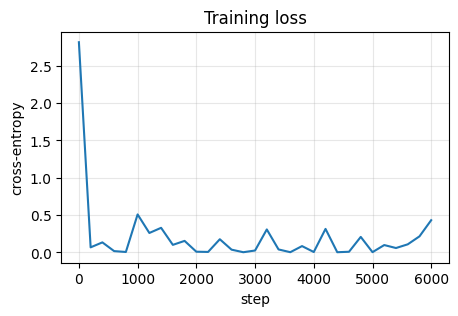

codebook (16, 7) | average energy per symbol = 1.0


In [2]:
model, hist = ex.train_model("ae74_awgn")
print("config:", ex.CFG["ae74_awgn"])
h = pd.DataFrame(hist, columns=["step", "loss"]); display(h.iloc[[0, len(h)//2, -1]])
plt.figure(figsize=(5, 3)); plt.plot(h.step, h.loss); plt.xlabel("step"); plt.ylabel("cross-entropy"); plt.title("Training loss"); plt.grid(alpha=.3); plt.show()
cb = model.codebook().detach().numpy()
print("codebook", cb.shape, "| average energy per symbol =", round(float((cb**2).mean()), 4))

## 2. Evaluate on identical information bits (and identical noise for the coded systems)
At each Eb/N0, 2.5 million messages (10 million information bits) are sent; the lowest plotted points (8 dB) have only ~50-100 bit errors and are statistically weak; points with zero errors are not plotted.

In [3]:
ae = load_model(ex.MODELS / "ae74_awgn.pt")
grid = np.arange(0, 9, 1.0)
df = ex.eval_74(ae, "awgn", grid, 2_500_000)
df.to_csv(ex.TAB / "ae74_awgn_results.csv", index=False)
display(df.pivot(index="ebn0_db", columns="method", values="ber").round(6))

method,autoencoder,hamming_hard,hamming_ml,uncoded_bpsk
ebn0_db,,,,
0.0,0.100638,0.119623,0.082740,0.078732
1.0,0.064672,0.084895,0.052291,0.056313
2.0,0.036922,0.055038,0.029042,0.037454
3.0,0.017786,0.031906,0.013684,0.022913
4.0,0.007231,0.016058,0.005280,0.012547
5.0,0.002205,0.006807,0.001578,0.005931
6.0,0.000502,0.002294,0.000364,0.002391
7.0,0.000084,0.000612,0.000052,0.000775
8.0,0.000009,0.000123,0.000005,0.000199


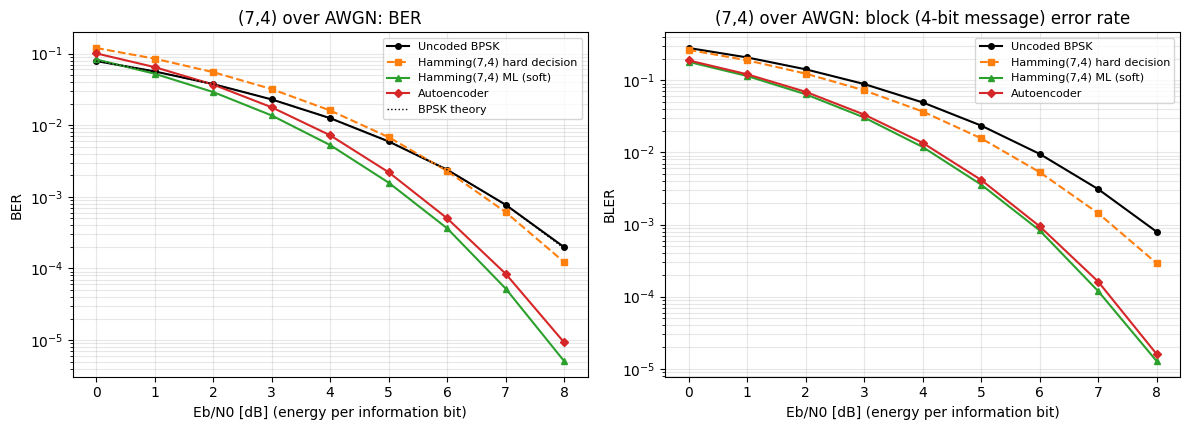

In [4]:
fig, axs = plt.subplots(1, 2, figsize=(12, 4.4))
ex.plot_curves(df, "ber", "(7,4) over AWGN: BER", ax=axs[0])
ex.plot_curves(df, "bler", "(7,4) over AWGN: block (4-bit message) error rate", ylabel="BLER", ax=axs[1])
axs[0].semilogy(grid, bl.q_bpsk_awgn(grid), "k:", lw=1, label="BPSK theory"); axs[0].legend(fontsize=8)
fig.tight_layout(); fig.savefig(ex.FIG / "ae74_awgn_ber_bler.png", dpi=150); plt.show()

## 3. Discussion

In [5]:
p = df.pivot(index="ebn0_db", columns="method", values="ber")
def snr_at(col, target):   # Eb/N0 at which the BER curve crosses `target` (log-linear interpolation)
    d = p[col][p[col] > 0]; return float(np.interp(np.log10(target), np.log10(d.values[::-1]), d.index.values[::-1]))
t = 1e-3
print({c: round(snr_at(c, t), 2) for c in ["uncoded_bpsk", "hamming_hard", "hamming_ml", "autoencoder"]}, "dB needed for BER = 1e-3")

{'uncoded_bpsk': 6.77, 'hamming_hard': 6.63, 'hamming_ml': 5.31, 'autoencoder': 5.53} dB needed for BER = 1e-3


* The autoencoder is clearly better than hard-decision Hamming decoding (about 0.9-1.1 dB less Eb/N0 for BER = 1e-2 / 1e-3 in the run above) because it, like ML, uses soft information. It is also better than uncoded BPSK for BER = 1e-3 by about 1.2 dB, but at very low SNR (about 1 dB and below) it is worse than uncoded BPSK.
* It does **not** reach Hamming-ML: it needs roughly 0.2-0.3 dB more Eb/N0 for the same BER (numbers printed above). Hamming-ML is the optimum decoder for the Hamming code, and the AE learns its code and decoder by gradient descent from noisy samples, so it can approach this reference but nothing forces it to match it; in this run it did not beat it.
* Coded curves start above uncoded BPSK at 0 dB because the code spends 7/4 times more symbols per information bit, so each symbol has less energy (Es = 4/7 Eb). Hamming-ML overtakes uncoded BPSK at about 1 dB, the AE at about 2 dB, and hard-decision Hamming only at about 6 dB.